
# CIS 415 HW3 Part 2: Customer Segmentation Analysis

## Introduction
In this assignment, you will apply K-Means clustering to segment customers based on their behavior. We will use the `HW3_Mall_Customers.csv` dataset, which includes information such as Customer ID, age, gender, annual income, and spending scores. The objective is to identify distinct groups within the mall customers to tailor marketing strategies accordingly.

## Dataset Description
The dataset includes the following columns:
- CustomerID: Unique identifier for the customer
- Gender: Gender of the customer
- Age: Age of the customer
- Annual Income (k$): Customer's annual income in thousands of dollars
- Spending Score (1-100): Score assigned by the mall based on customer behavior and spending nature

## Learning Outcomes
By completing this assignment, you will learn:
- How to perform exploratory data analysis on a real-world dataset.
- How to apply preprocessing techniques to prepare data for clustering.
- How to implement K-Means clustering in Python using scikit-learn.
- How to interpret the results of clustering and identify customer segments.

## Instructions
Follow the steps outlined below, filling in code as necessary and answering the analysis questions.


In [1]:
# Import necessary libraries

import random 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.cluster import KMeans 
from sklearn.datasets import make_blobs 
import pandas as pd
%matplotlib inline
# Suppress warning messages (this makes your report cleaner)

def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn


### Part 1: Data Loading and Exploration
Load the dataset and conduct an exploratory data analysis to familiarize yourself with the data.


In [2]:
# Load the dataset

import pandas as pd
cust_df = pd.read_csv("HW3_mall_customers.csv")

# Display the first few rows of the dataset
cust_df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
# Summary statistics of the dataset.
cust_df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


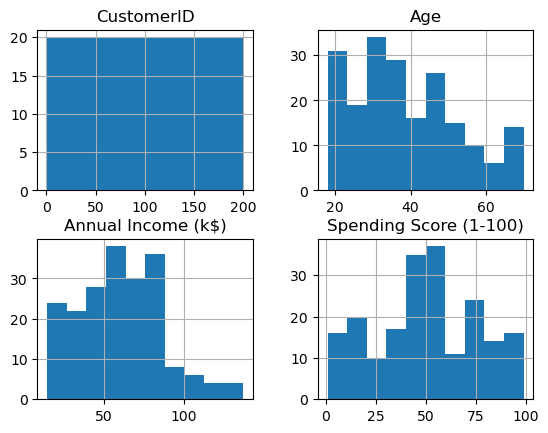

In [4]:
# Visualize the dataset, histograms, scatterplots, etc

#Histogram of all of the numeric features against spending socre 
cust_df.hist()
plt.show()

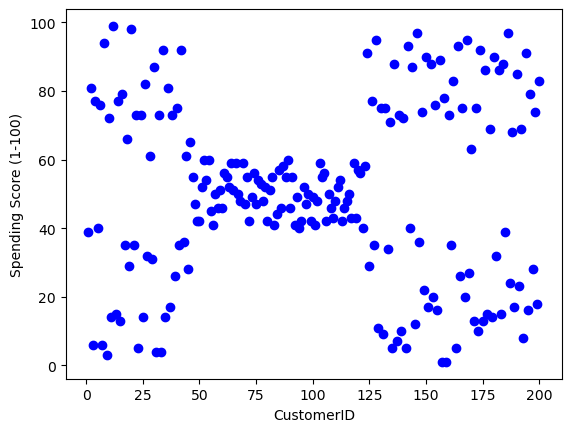

In [5]:
#Scatterplot of CustomerID against Spending Score
plt.scatter(x=cust_df["CustomerID"], y=cust_df["Spending Score (1-100)"], color='blue')
plt.xlabel("CustomerID")
plt.ylabel("Spending Score (1-100)")
plt.show()

#This is showing a very interesting relationship between CustomerID and Spending Score. 
#You can see multiple groups of datapoints clustered together. 



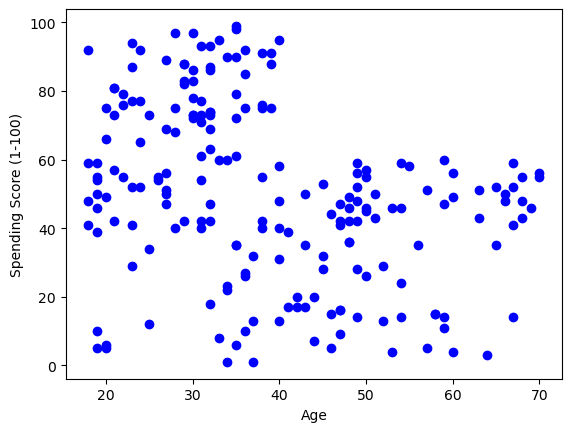

In [6]:
#Scatterplot of Age against Spending Score
plt.scatter(x=cust_df["Age"], y=cust_df["Spending Score (1-100)"], color='blue')
plt.xlabel("Age")
plt.ylabel("Spending Score (1-100)")
plt.show()

#This is showing a negative relationship between age and spending socre. 
#As people get older, there spending score tends to decrease.
#This is expected because when people are younger, they are less knowledgeable on how to manage their spending.
#Therefore, this tends to lead to bad spending habits which increases their spending score. 


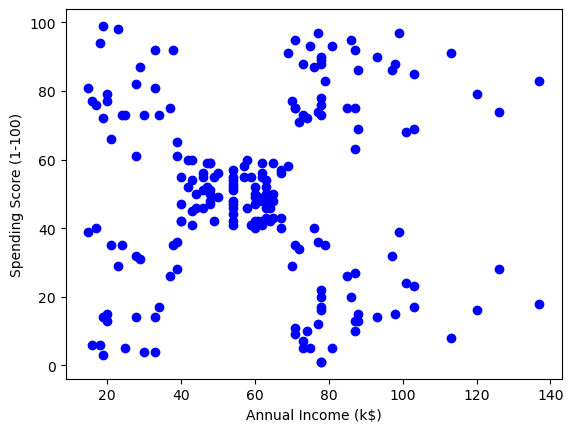

In [7]:
#Scatterplot of Annual Income (k$) against Spending Score
plt.scatter(x=cust_df["Annual Income (k$)"], y=cust_df["Spending Score (1-100)"], color='blue')
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.show()

#Like the visualization of customer id against spending score, we can see mutliple groups of datapoints that are clustered together.
#The overall trend indicates that people with lower income tends to have a higher spending score.
#This makes sense because a lot of people have low incomes due to overspending. 




### Part 2: Data Preprocessing
Preprocess the data by encoding categorical variables if necessary, and scaling the features.


In [8]:
#Dropping the genre column since its categorical. 
#The K-Means clustering can only take in numeric values. 
df = cust_df.drop('Genre', axis=1) #Using the drop method to drop Genre
df.head() #Displaying the numeric results 


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,2,21,15,81
2,3,20,16,6
3,4,23,16,77
4,5,31,17,40



### Part 3: Applying K-Means Clustering
Implement K-Means clustering on the preprocessed data and identify the optimal number of clusters using the elbow method. The elbow method is a heuristic used in determining the number of clusters in a data set. The method consists of plotting the explained variation as a function of the number of clusters, and picking the elbow of the curve as the number of clusters to use. This is a visual method and is subjective, but it provides a good starting point. In this plot, you would typically look for the "elbow" point, where the rate of decrease sharply changes. This point indicates the optimal number of clusters in terms of the WCSS metric. Beyond this point, adding more clusters doesn't provide as much benefit. Here are some sample codes you can use for this assignment. 

    wcss = []
    for i in range(1, 11):
        kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
        kmeans.fit(X)
        wcss.append(kmeans.inertia_)
    
    # Plot the WCSS values
    plt.plot(range(1, 11), wcss)
    plt.title('The Elbow Method')
    plt.xlabel('Number of clusters')
    plt.ylabel('WCSS') # Within-Cluster Sum of Square
    plt.show()


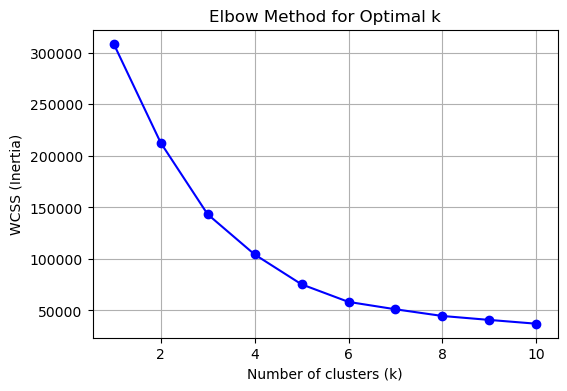

In [9]:
#Use the elbow method to determine the number of clusters.
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

# Example data: X (your data points)
X = df[['Annual Income (k$)', 'Age', 'Spending Score (1-100)']].values

wcss = []  # within-cluster sum of squares
# wcss shows how tightly the data points are grouped around their cluster centers (centroids).
# It’s basically a number that tells you how compact your clusters are.
# Small WCSS → points are close to their centroids → good clustering.
# Large WCSS → points are spread out → poor clustering.

# Try different k values
for k in range(1, 11):  # test k = 1 to 10
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=12, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)  # inertia_ = total WCSS

# Plot the elbow curve
plt.figure(figsize=(6,4))
plt.plot(range(1, 11), wcss, 'bo-')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

#The optimal number of k is 5 since at k=5, the line starts to dramatically steady. 
#The WCCS drops drops rapidly from k=1 to k=5 and then levels off once it his k=5.
#This leveling indicates diminishing returns, so k=5 is a good balance between low error and simplicity.


In [10]:
#Normalizing over the standard deviation 
from sklearn.preprocessing import StandardScaler       # Import StandardScaler to normalize data before clustering

X = df.values[:, 1:]                                   # Extract all rows and columns starting from index 1 (skip the first column, e.g., customer ID)
X = np.nan_to_num(X)                                   # Replace any missing (NaN) or infinite values with 0 or finite numbers
Clus_dataSet = StandardScaler().fit_transform(X)       # Standardize features by removing the mean and scaling to unit variance
Clus_dataSet                                           # Display the transformed dataset


array([[-1.42456879, -1.73899919, -0.43480148],
       [-1.28103541, -1.73899919,  1.19570407],
       [-1.3528021 , -1.70082976, -1.71591298],
       [-1.13750203, -1.70082976,  1.04041783],
       [-0.56336851, -1.66266033, -0.39597992],
       [-1.20926872, -1.66266033,  1.00159627],
       [-0.27630176, -1.62449091, -1.71591298],
       [-1.13750203, -1.62449091,  1.70038436],
       [ 1.80493225, -1.58632148, -1.83237767],
       [-0.6351352 , -1.58632148,  0.84631002],
       [ 2.02023231, -1.58632148, -1.4053405 ],
       [-0.27630176, -1.58632148,  1.89449216],
       [ 1.37433211, -1.54815205, -1.36651894],
       [-1.06573534, -1.54815205,  1.04041783],
       [-0.13276838, -1.54815205, -1.44416206],
       [-1.20926872, -1.54815205,  1.11806095],
       [-0.27630176, -1.50998262, -0.59008772],
       [-1.3528021 , -1.50998262,  0.61338066],
       [ 0.94373197, -1.43364376, -0.82301709],
       [-0.27630176, -1.43364376,  1.8556706 ],
       [-0.27630176, -1.39547433, -0.590

In [11]:
# Apply K-Means clustering using the number of clusters you have identified.
clusterNum = 5                                                    # Set the number of clusters we want the algorithm to find
k_means = KMeans(init="k-means++", n_clusters=clusterNum, n_init=12)   # Create a K-Means model: smart initialization, 3 clusters, 12 random starts
k_means.fit(X)                                                    # Train (fit) the K-Means model using the dataset X
labels = k_means.labels_                                          # Retrieve the cluster label (0, 1, 2) assigned to each data point
print(labels)



[3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3
 4 3 4 3 4 3 4 3 4 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 2 1 0 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 0 1 2 1 2 1
 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2
 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1]


In [12]:

# We assign the labels to each row in the dataframe.
df["Clus_km"] = labels
df.head(60) # 0: group 1, 1: group 2, 2: group 3, 3: group 4, 4: group 5

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Clus_km
0,1,19,15,39,3
1,2,21,15,81,4
2,3,20,16,6,3
3,4,23,16,77,4
4,5,31,17,40,3
5,6,22,17,76,4
6,7,35,18,6,3
7,8,23,18,94,4
8,9,64,19,3,3
9,10,30,19,72,4



### Part 4: Analysis of Clusters
Analyze the clusters formed and visualize the results. Then, interpret the characteristics of each cluster.


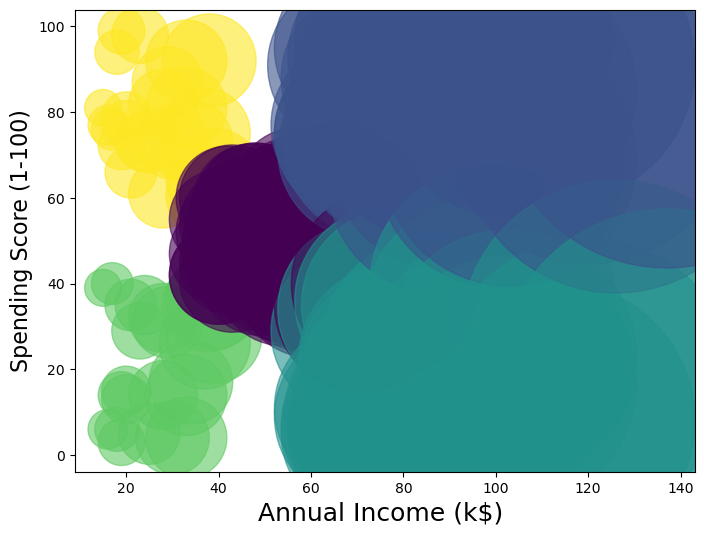

In [13]:

area = np.pi * (X[:, 1])**2    # Compute bubble size based on segment
plt.figure(figsize=(8,6))
plt.scatter(X[:, 1], X[:, 2], s=area,              # Plot data points: X-axis = Annual Income, Y-axis = Spending Score
            c=labels.astype(float), cmap='viridis' ,alpha=0.6)     # Color by cluster label, add transparency for overlapping points
plt.xlabel('Annual Income (k$) ', fontsize=18)                     # Label the x-axis
plt.ylabel('Spending Score (1-100)', fontsize=16)                  # Label the y-axis
plt.show()                                         # Display the scatter (bubble) chart


In [14]:
#Analysis:
#Cluster 0 (Cyan): Lower annual salary, lower spending score, covers a small portion of the data 
#Cluster 1 (Blue):  Lower annual salary, moderate spending score, covers a small portion of the data
#Cluster 2 (Purple): Lower annual salary, higher spending score, covers a small poriton of the data
#Cluster 3 (Yellow): Moderate to high annual salary, lower spending score, covers a large portion of the data
#Cluster 4 (Green): Moderate to high annual salary, moderate to high spending score, covers a large portion of the data 


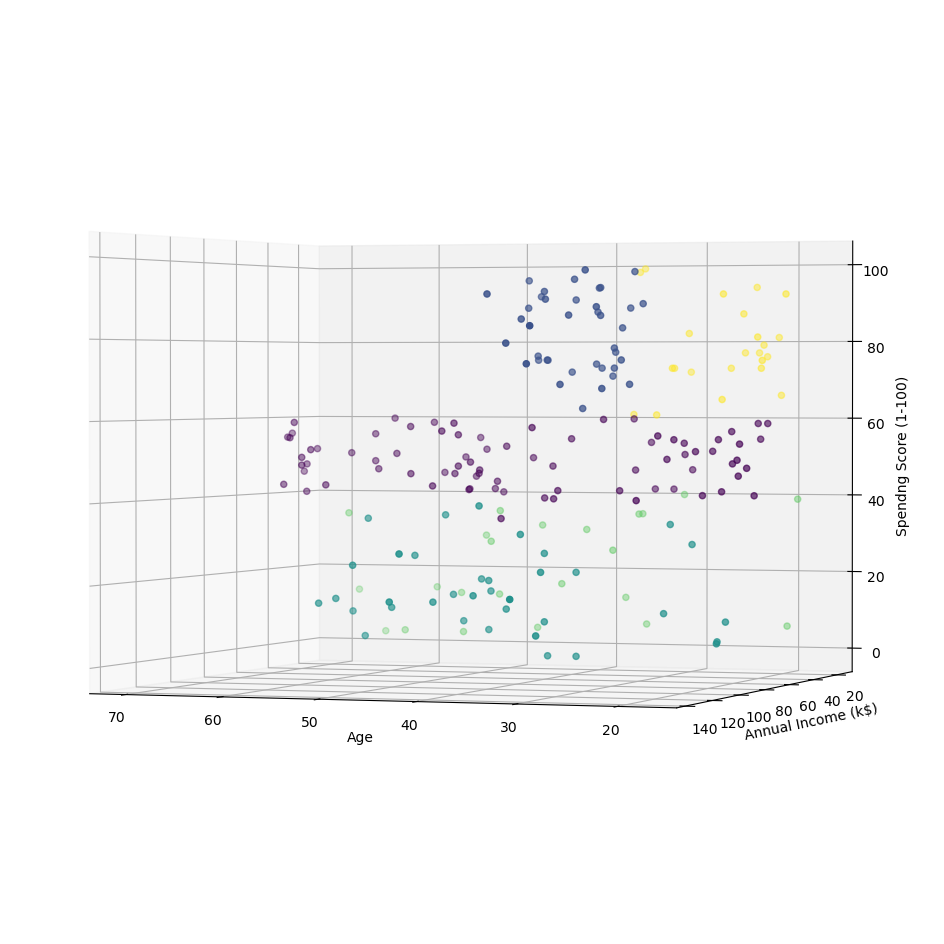

In [15]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
# Create a new figure with a specified figure size
fig = plt.figure(figsize=(16, 12))

# Add a 3D subplot
# The 'projection' argument is used to create a 3D axes
# 111 - 1 column, 1 row, 1 index => Create one single subplot that occupies the entire figure.
# elev = elevation angle (how high the camera is above the plot, in degrees).
# A higher number tilts the view downward, like looking from above.
# azim = azimuth angle (rotation around the vertical axis, also in degrees). This rotates our 3D view left or right.
 

ax = fig.add_subplot(111, projection='3d', elev=1, azim=110) #elev and azim allow you to view the segmentation in different ways

# Set labels for axes
ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spendng Score (1-100)')

# Assuming 'X' is a 2D data array and 'labels' is an array of labels
# Scatter plot for 3D data
# Make sure 'X' and 'labels' are defined before this step
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=labels.astype(float))

# Display the plot
plt.show()

In [16]:
#This view is showing that younger people tend to have higher spending scores. 
#This makes sense since they haven't had as much experience with managing their money.


### Analysis Questions

1. Describe any patterns or trends you observe in the distribution of the 'Annual Income' and 'Spending Score'..
3. How did you determine the optimal number of clusters for this dataset?
4. Provide a detailed interpretation of each cluster and discuss how a mall could use this information in its marketing strategy.
5. What other features could be included in this dataset to further refine the customer segmentation?
6. Reflect on the limitations of K-Means clustering. Are there scenarios where it might not be the best algorithm to use?



Write your answers here.
1. I noticed that annual income does not have an impact on spending score.
2. You determine the optimal number of clusters by looking for the k data
   point where the line starts to level off.
3. Cluster 0 (Cyan): Lower annual salary, lower spending score, covers a small portion of the data 
   Cluster 1 (Blue):  Lower annual salary, moderate spending score, covers a s small portion of the data
    Cluster 2 (Purple): Lower annual salary, higher spending score, covers a small poriton of the data
    Cluster 3 (Yellow): Moderate to high annual salary, lower spending score, covers a large portion of the data
    Cluster 4 (Green): Moderate to high annual salary, moderate to high spending score, covers a large portion of the data 
   They could use this information to help show the trend of how customers are
   managing their spending and what issues tend to occur based on certain features regarding them. 
4. The mall should create some sort of a recommendation feature for when a customer is purchasing a product. The recommendation system should view how much money they have on the card their using and decide whether its worth investing in that product. I also think this would be a great addition because a lot of the customers at the mall tend to be younger indivudals and they likely have less experience with managing their own money. This will help people become smarter with managing their income and help prevent spending scores from getting too high.
5. The K-Means clustering is a great too to use for semengation purposes but
   it also has its limitations. When it comes to detecting outliers, its not
   going to be useful becuase its shading groups of similar data points and this hides any outliers. In addition, k-means can only work with numerical data since it uses eucledian distance and that measurement doesn't work on categorical data. 

### Good luck and have fun with K-Means! :) Dr. Wang